# Los equipos de perforación, vistos con radar

Los notebooks 01 y 02 ven la locación cuando se construye; el 03 y el 04, las antorchas. Falta lo que pasa en
el medio: cuándo llega el equipo que perfora y cuándo se va. Con una imagen óptica por mes no alcanza, y en
invierno las nubes tapan semanas enteras.

El radar de Sentinel-1 no depende del sol ni de las nubes. Un equipo de perforación es una torre de metal de
unos 40 metros: en el radar es un punto muy brillante sobre una locación que antes era oscura, y además
**despolariza**, es decir, también brilla en el canal cruzado (VH), cosa que el suelo y casi todo lo demás
no hacen. Cuando el equipo se va, el brillo se apaga.

La búsqueda es a ciegas: el detector no mira el padrón. Las fechas de inicio y fin de perforación de cada
pozo del Capítulo IV se usan solo para medir.

- Datos: Sentinel-1 RTC (corregido por terreno) de Microsoft Planetary Computer, procesado por Catalyst, CC BY
  4.0. Siempre la misma órbita (18 ascendente), para que la geometría no cambie: una pasada cada 12 días, y cada
  6 entre abril de 2025 y junio de 2026.
- Tres ventanas con serie desde 2023 sirven para medir: con **Loma Campana este** se eligió la regla; **Bajada
  del Palo y Bandurria** y **Bajada del Palo este** son la prueba, sin tocar nada. Las otras doce, desde agosto
  de 2025, entran al tablero.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
from loclab import DATA_PROC, DATA_RAW, FIGURES, ZONAS, radar
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
VALIDACION, AJUSTE = ["loma_campana_este", "norte_lac_bdp_bandurria", "norte_este"], "loma_campana_este"
for z in ZONAS:
    f = radar.fechas(z)
    if len(f):
        print(f"{z:26s} {len(f):4d} pasadas del {f.min():%d/%m/%Y} al {f.max():%d/%m/%Y}")

loma_campana_oeste           63 pasadas del 03/08/2025 al 15/11/2026
norte_lac_bdp_bandurria     144 pasadas del 04/01/2023 al 15/11/2026
loma_campana_este           144 pasadas del 04/01/2023 al 15/11/2026
fortin_de_piedra             63 pasadas del 03/08/2025 al 15/11/2026
norte_este                  144 pasadas del 04/01/2023 al 15/11/2026
norte_norte                  63 pasadas del 03/08/2025 al 15/11/2026
norte_noreste                63 pasadas del 03/08/2025 al 15/11/2026
aguada_pichana_oeste         63 pasadas del 03/08/2025 al 15/11/2026
aguada_pichana_este          63 pasadas del 03/08/2025 al 15/11/2026
sierras_blancas              63 pasadas del 03/08/2025 al 15/11/2026
loma_la_lata_sur             63 pasadas del 03/08/2025 al 15/11/2026
aguada_del_chanar            63 pasadas del 03/08/2025 al 15/11/2026
rincon_del_mangrullo         63 pasadas del 03/08/2025 al 15/11/2026
ypf_sur_este                 63 pasadas del 03/08/2025 al 15/11/2026
aguada_pichana_norte         63 pa

## 1. Mientras se perfora, la locación brilla

Primero sin detector: para cada locación del padrón en las tres ventanas, el punto más brillante en 60 m
alrededor de los pozos, en cada pasada, separado según la fase en que estaba la locación según el padrón.

In [2]:
s = pd.read_csv(DATA_PROC / "radar_brillo_fases.csv")
t = s.groupby("fase").vv_max.agg(pasadas="size", mediana_dB="median", mas_de_5dB=lambda x: (x > 5).mean() * 100)
t.reindex(["antes", "perforación", "espera", "terminación", "producción"]).round(1)

,pasadas,mediana_dB,mas_de_5dB
fase,,,
antes,4539,-9.6,1.4
perforación,972,7.0,72.2
espera,316,-8.2,2.5
terminación,323,1.8,18.9
producción,67677,-6.2,1.0


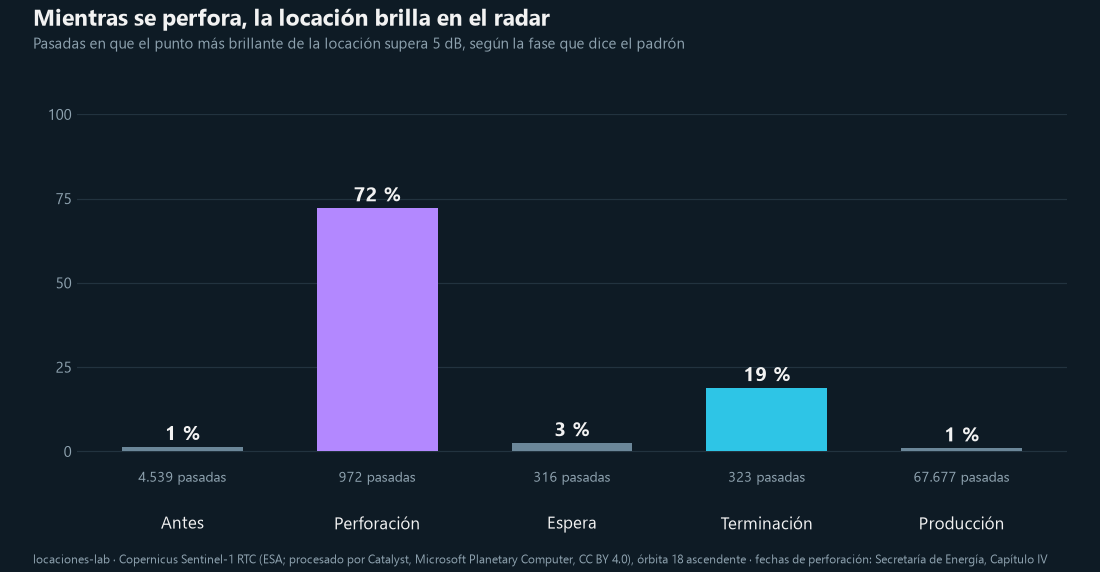

In [3]:
display(Image(FIGURES / "radar_fases.png"))

Antes de perforar y con la locación en producción, el radar casi nunca pasa los 5 dB. Mientras hay equipo,
sí. En la terminación (la fractura) también hay equipos, más bajos y por menos tiempo.

## 2. El detector a ciegas

Pasada por pasada, sin mirar el padrón:

1. Se quita el efecto del suelo mojado o seco, que sube o baja toda la escena.
2. Se calcula el brillo de siempre de cada píxel: la mediana de toda la serie.
3. Un punto se enciende si supera 5 dB y está 6 dB por encima de su brillo de siempre.
4. Las detecciones a menos de 60 m en pasadas distintas son el mismo objeto; si no se lo ve en 40 días, se fue.

Eso encuentra de todo: equipos, sets de fractura, camiones en las playas de Añelo, grúas de una planta en obra.
La regla, elegida mirando solo Loma Campana este, se queda con lo que parece un equipo:

- visto en **3 pasadas o más**;
- **VH máximo por encima de −4 dB**: la torre despolariza;
- el lugar **casi siempre es oscuro** (brillo de siempre por debajo de −5 dB): una locación, no una planta;
- **sobre una locación**: un pozo del padrón a menos de 150 m, una locación que vio Sentinel-2 a menos de 200 m,
  o un rectángulo claro en la última imagen óptica; y a más de 3 km de Añelo.

In [4]:
e = pd.concat([pd.read_csv(DATA_PROC / f"radar_eventos_{z}.csv") for z in ZONAS if (DATA_PROC / f"radar_eventos_{z}.csv").exists()])
eq = pd.read_csv(DATA_PROC / "radar_equipos.csv", parse_dates=["llegada", "salida"])
print(f"{len(e):,} objetos que se encendieron · {int((e.pasadas >= 3).sum()):,} vistos en 3 pasadas o más · {len(eq)} pasan la regla".replace(",", "."))
print("dónde cayeron:", eq.lugar.value_counts().to_dict())

4.736 objetos que se encendieron · 1.451 vistos en 3 pasadas o más · 351 pasan la regla
dónde cayeron: {'pozo del padrón': 287, 'locación de Sentinel-2': 48, 'locación nueva (óptico)': 16}


## 3. Contra el padrón

Dos preguntas:

- **¿Lo ve?** De las locaciones que se perforaron enteras dentro del período, en cuántas hubo un equipo encima
  mientras se perforaba, y con qué diferencia de fechas.
- **¿Lo que ve es un equipo?** Qué dice el padrón debajo de cada equipo detectado, hasta febrero de 2026 (el
  padrón carga los pozos con unos seis meses de demora).

In [5]:
r = pd.read_csv(DATA_PROC / "radar_recall.csv")
filas = []
for nombre, zs in (("ajuste (Loma Campana este)", [AJUSTE]), ("prueba (las otras dos)", [z for z in VALIDACION if z != AJUSTE])):
    rr = r[r.zona.isin(zs)]
    ee = eq[eq.zona.isin(zs) & eq.tipo.notna()]
    filas.append({"ventanas": nombre, "locaciones perforadas": len(rr), "con equipo visto": int(rr.visto.sum()),
                  "%": round(rr.visto.mean() * 100), "llegada − inicio (días)": rr.llegada.median(), "salida − fin (días)": rr.salida.median(),
                  "equipos detectados": len(ee), "sobre perforación o terminación": int(ee.tipo.isin(["perforación", "terminación"]).sum())})
pd.DataFrame(filas).set_index("ventanas")

,locaciones perforadas,con equipo visto,%,llegada − inicio (días),salida − fin (días),equipos detectados,sobre perforación o terminación
ventanas,,,,,,,
ajuste (Loma Campana este),23,20,87,13.5,2.5,42,38
prueba (las otras dos),97,86,89,13.0,1.0,135,129


El equipo aparece en promedio unas dos semanas después del inicio de perforación que dice el padrón. Parte es
la revisita (una pasada cada 12 días en 2023 y 2024) y parte es cómo se perfora en Vaca Muerta: primero un
equipo chico hace la boca de todos los pozos de la locación y después llega el grande. La salida coincide casi
con el día.

## 4. Un caso

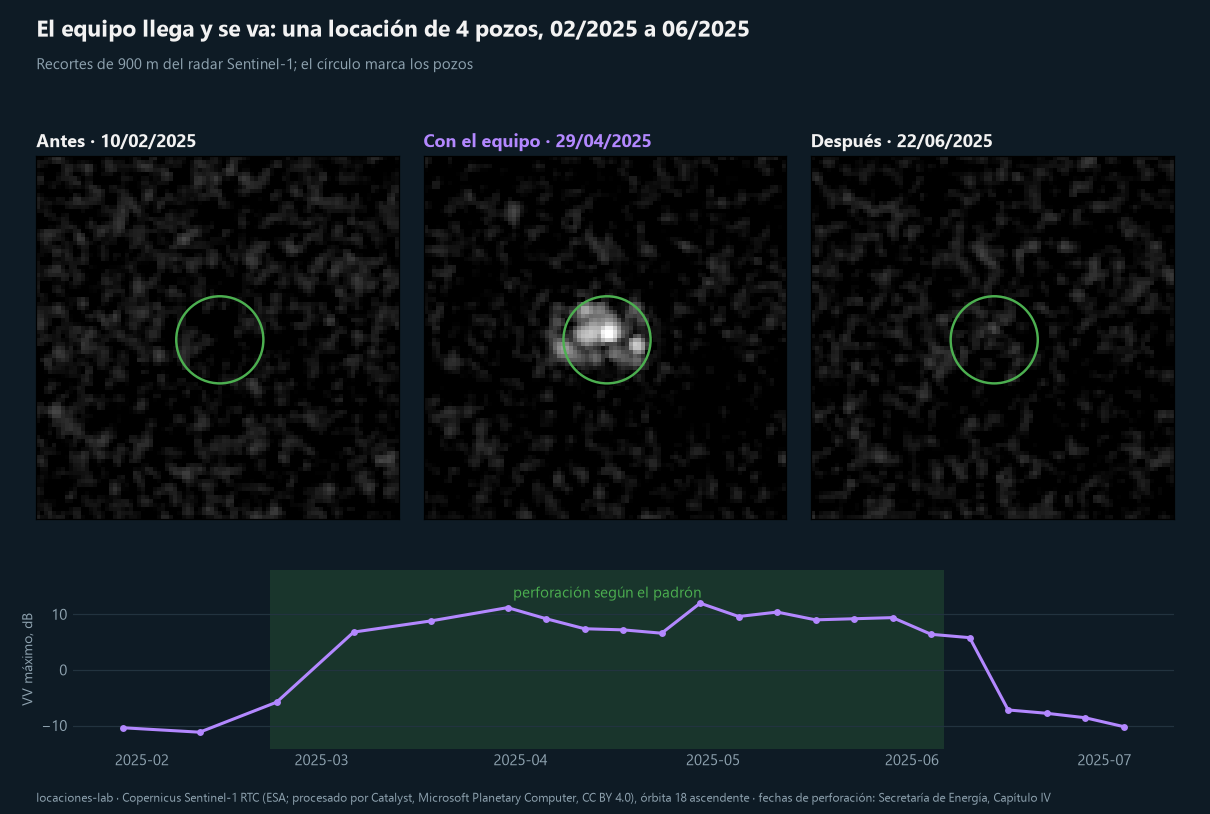

In [6]:
display(Image(FIGURES / "radar_caso.png"))

## 5. Contar equipos por mes

Juntando los eventos de una misma locación en campañas, se puede contar cuántos equipos trabajan cada mes y
compararlo con cuántas locaciones se estaban perforando según el padrón.

2023-02 a 2025-03 (una pasada cada 12 días): radar 10.9 equipos por mes · padrón 16.0 locaciones · correlación 0.48
2025-04 a 2026-02 (una pasada cada 6 días): radar 14.2 equipos por mes · padrón 13.1 locaciones · correlación 0.69


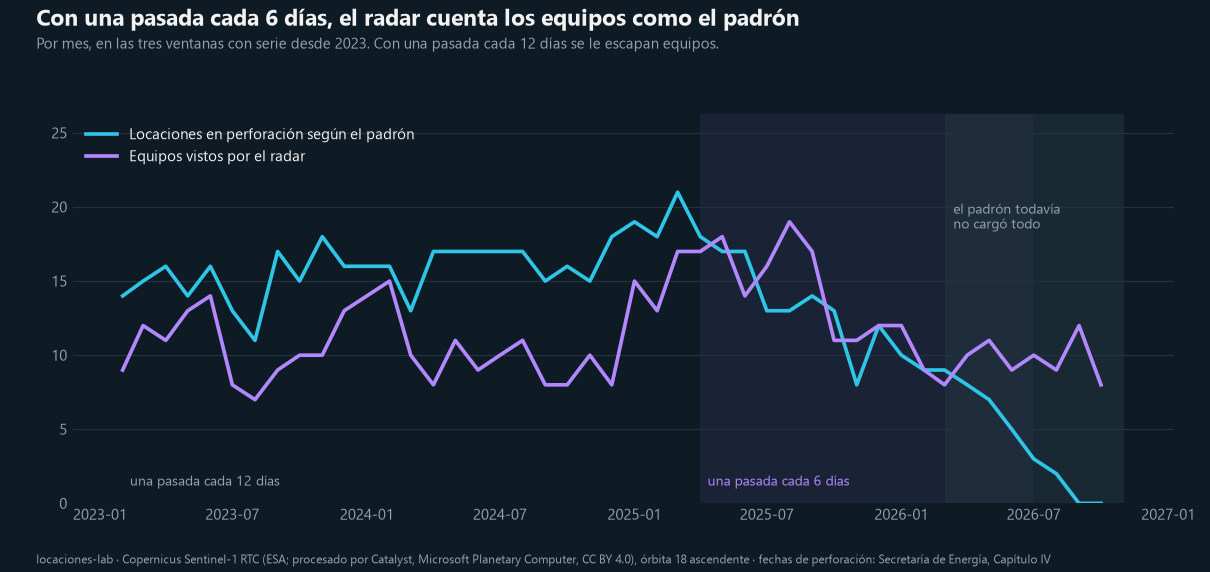

In [7]:
t = pd.read_csv(DATA_PROC / "radar_conteo_mensual.csv")
for a, b, que in (("2023-02", "2025-03", "una pasada cada 12 días"), ("2025-04", "2026-02", "una pasada cada 6 días")):
    u = t[(t.mes >= a) & (t.mes <= b)]
    print(f"{a} a {b} ({que}): radar {u.radar.mean():.1f} equipos por mes · padrón {u.padron.mean():.1f} locaciones · correlación {u.radar.corr(u.padron):.2f}")
display(Image(FIGURES / "radar_conteo.png"))

Con una pasada cada 6 días los dos conteos van juntos. Con una cada 12 días el radar se pierde equipos: una
campaña corta puede caer entre dos pasadas, y una larga se corta en dos o se acorta. Desde julio de 2026 la
órbita volvió a pasar cada 12 días, así que el conteo de hoy probablemente se queda corto.

## 6. Hoy

In [8]:
c = pd.read_csv(DATA_PROC / "radar_campanias.csv", parse_dates=["llegada", "salida", "ultima_pasada"])
act = c[c.activa]
print(f"{len(c)} campañas en las quince ventanas · en la última pasada ({c.ultima_pasada.max():%d/%m/%Y}) siguen trabajando {len(act)}")
act.groupby("zona").size().rename("equipos activos").to_frame()

226 campañas en las quince ventanas · en la última pasada (15/11/2026) siguen trabajando 19


,equipos activos
zona,
aguada_pichana_este,1
aguada_pichana_oeste,1
loma_campana_este,2
loma_campana_oeste,1
loma_la_lata_sur,5
norte_este,1
norte_lac_bdp_bandurria,2
norte_norte,1
rincon_del_mangrullo,2


Las coordenadas de los equipos que están sobre locaciones sin pozo en el padrón no se publican: en el tablero
público entran solo como conteo.

## Lo que falta

- **Qué equipo es.** El radar ve una torre; no distingue un equipo de perforación de uno de reparación de
  pozos, y la terminación también enciende la locación. El padrón lo dice después.
- **La regla** se eligió con una ventana y se probó con dos de la misma zona norte. En las otras doce no hay
  serie desde 2023 para medirla: revisé a ojo los activos de hoy y la mayoría está sobre una locación con
  equipo, pero hay algunos dudosos (obras en construcción, instalaciones nuevas).
- **El contraste óptico** (el tercer criterio de "sobre una locación") se eligió mirando esos mismos casos.